# UNSW-NB15 — Model Training, Evaluation, and Interpretability

**Project:** Machine Learning-Based Network Intrusion Detection and Analytics System  
**Dataset:** UNSW-NB15 (official predefined train/test split)  
**Phases covered:** 3 (Preprocessing), 4 (Model Training), 5 (Interpretability)  

## Design note

Model training (~20 s) and interpretation scripts were run once and their results persisted to disk.  
This notebook **loads the saved artifacts** rather than retraining models, so it runs in seconds.  
All metrics shown here come from the saved JSON files; they were **not manually edited**.

To fully regenerate artifacts from scratch:
```
.venv\Scripts\python.exe scripts/run_training.py
.venv\Scripts\python.exe scripts/run_interpret.py
```

## Outputs from previous runs (already on disk)
| Artifact | Path |
|---|---|
| Fitted pipelines | `models/` |
| Per-model metrics JSON | `results/metrics/metrics_<Model>.json` |
| Comparison summary | `results/metrics/model_comparison.json` |
| Interpretation summary | `results/metrics/interpretation_summary.json` |
| Confusion matrices | `results/figures/confusion_matrix_<Model>.png` |
| ROC curves | `results/figures/roc_curves.png` |
| Model comparison chart | `results/figures/model_comparison.png` |
| Feature importance chart | `results/figures/feature_importance_rf.png` |
| Error distributions chart | `results/figures/error_distributions_rf.png` |

## 0. Imports and paths

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

METRICS_DIR = PROJECT_ROOT / 'results' / 'metrics'
FIGURES_DIR = PROJECT_ROOT / 'results' / 'figures'
MODELS_DIR  = PROJECT_ROOT / 'models'

print('Project root:', PROJECT_ROOT)
print('Metrics dir: ', METRICS_DIR)
print('Figures dir: ', FIGURES_DIR)

Project root: C:\Users\meema\ML_Network_Intrusion_Detection
Metrics dir:  C:\Users\meema\ML_Network_Intrusion_Detection\results\metrics
Figures dir:  C:\Users\meema\ML_Network_Intrusion_Detection\results\figures


## 1. Preprocessing design recap

The leakage-safe preprocessing pipeline (built in Phase 3) is embedded inside every saved model `Pipeline` object. Key design decisions:

| Decision | Detail |
|---|---|
| Excluded columns | `label` (target), `attack_cat` (leaks outcome), `id` (identifier only) |
| Numeric features (39) | `SimpleImputer(median)` + `StandardScaler` |
| Categorical features | `SimpleImputer(most_frequent)` + `OneHotEncoder(handle_unknown='ignore')` |
| `proto` cardinality cap | `max_categories=20` — 133 training values; top-10 cover 92.9% of rows |
| Train-only fitting | All preprocessing statistics computed on training data only |
| Output feature dimension | 81 columns (39 numeric + 20 proto + 13 service + 9 state) |

> `handle_unknown='ignore'` is required: EDA confirmed `state` has 2 test-only values ('ACC', 'CLO').

## 2. Load saved model-comparison results

In [2]:
comparison = json.loads((METRICS_DIR / 'model_comparison.json').read_text())

rows = []
for model, m in comparison.items():
    rows.append({
        'Model':             model,
        'Accuracy':          m['accuracy'],
        'Attack Recall':     m['attack_recall'],
        'Attack Precision':  m['attack_precision'],
        'Macro F1':          m['macro_f1'],
        'ROC-AUC':           m.get('roc_auc', 'N/A'),
        'Train (s)':         m['train_time_s'],
        'FN (missed atks)':  m['fn'],
        'FP (false alarms)': m['fp'],
    })

df_cmp = pd.DataFrame(rows).set_index('Model')
print('Source: results/metrics/model_comparison.json — values are from saved artifacts, not recomputed here.')
display(df_cmp)

Source: results/metrics/model_comparison.json — values are from saved artifacts, not recomputed here.


,Accuracy,Attack Recall,Attack Precision,Macro F1,ROC-AUC,Train (s),FN (missed atks),FP (false alarms)
Model,,,,,,,,
DummyClassifier,0.5506,1.0000,0.5506,0.3551,0.5000,1.805,0,37000
LogisticRegression,0.8089,0.9724,0.7527,0.7948,0.9551,9.475,1253,14481
RandomForest,0.8726,0.9858,0.8194,0.8665,0.9789,8.744,642,9850


**How to read the metrics:**

- **Attack Recall** = fraction of real attacks correctly identified. Low value = missed attacks.
- **Attack Precision** = fraction of 'attack' predictions that are correct. Low value = false alarms.
- **FN (False Negatives)** = attacks predicted as normal — the most dangerous outcome.
- **FP (False Positives)** = normal traffic predicted as attack — causes alert fatigue.
- **Accuracy** alone is misleading: the Dummy baseline reaches 55% by always predicting 'attack'.

The **Dummy baseline** proves any real classifier must outperform trivial majority-class prediction.
The test set has 55% attacks, so always predicting 'attack' gives 55% accuracy with 37,000 false alarms.

## 3. Confusion matrices

--- DummyClassifier ---


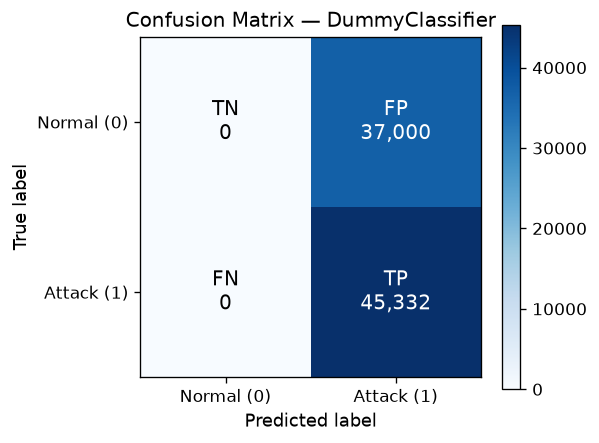

--- LogisticRegression ---


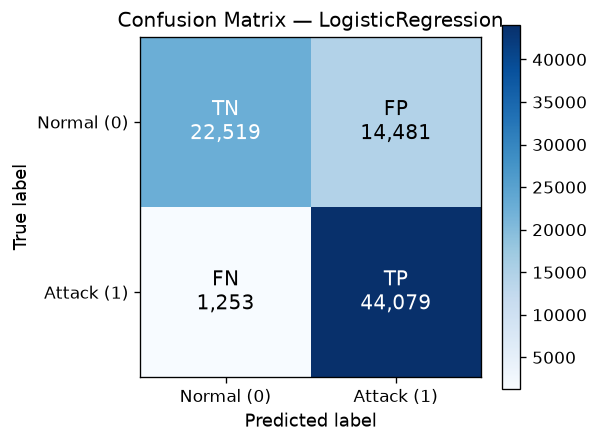

--- RandomForest ---


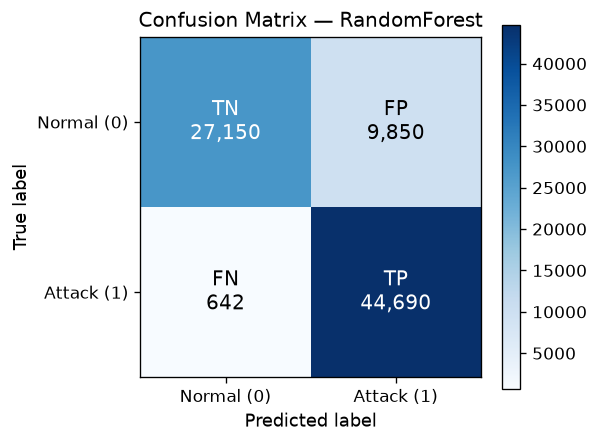

In [3]:
for model in ['DummyClassifier', 'LogisticRegression', 'RandomForest']:
    fig_path = FIGURES_DIR / f'confusion_matrix_{model}.png'
    if fig_path.exists():
        print(f'--- {model} ---')
        display(Image(filename=str(fig_path), width=400))

## 4. ROC curves

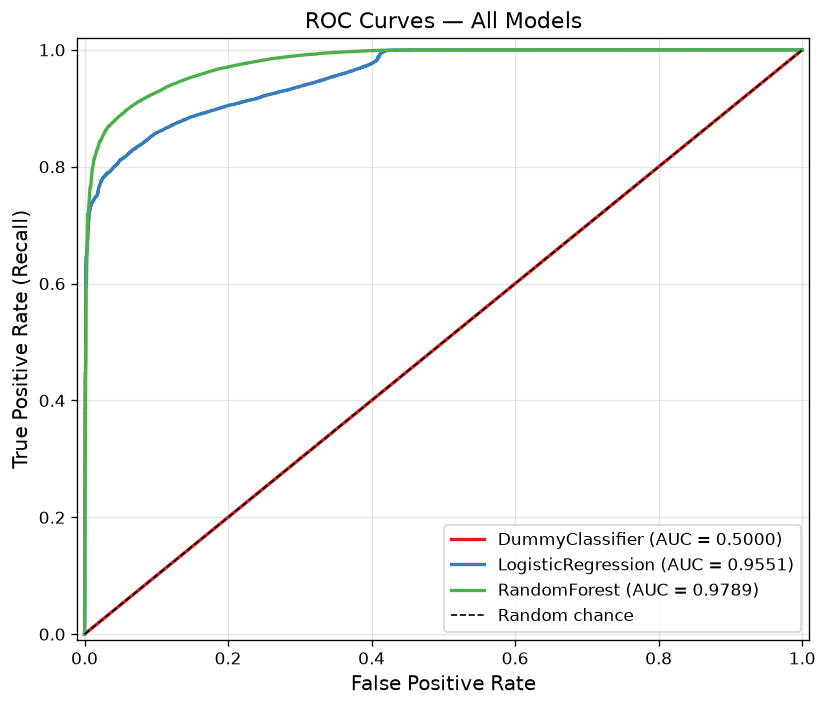

In [4]:
roc_path = FIGURES_DIR / 'roc_curves.png'
if roc_path.exists():
    display(Image(filename=str(roc_path), width=600))

## 5. Model comparison chart

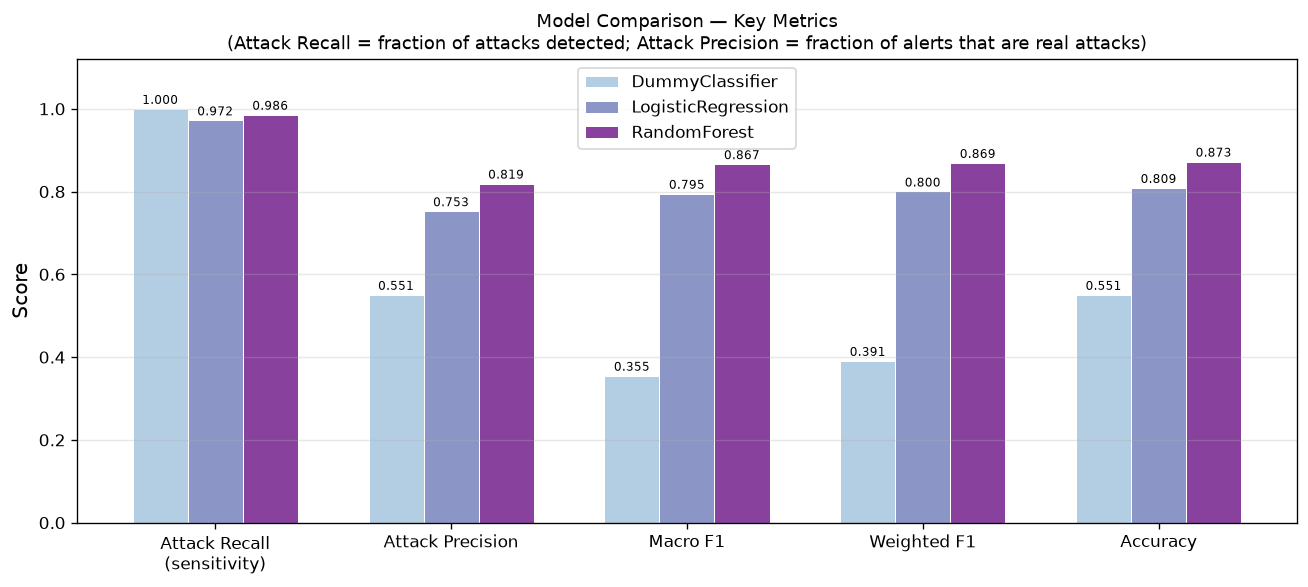

In [5]:
cmp_path = FIGURES_DIR / 'model_comparison.png'
if cmp_path.exists():
    display(Image(filename=str(cmp_path), width=750))

## 6. Feature importance (Random Forest)

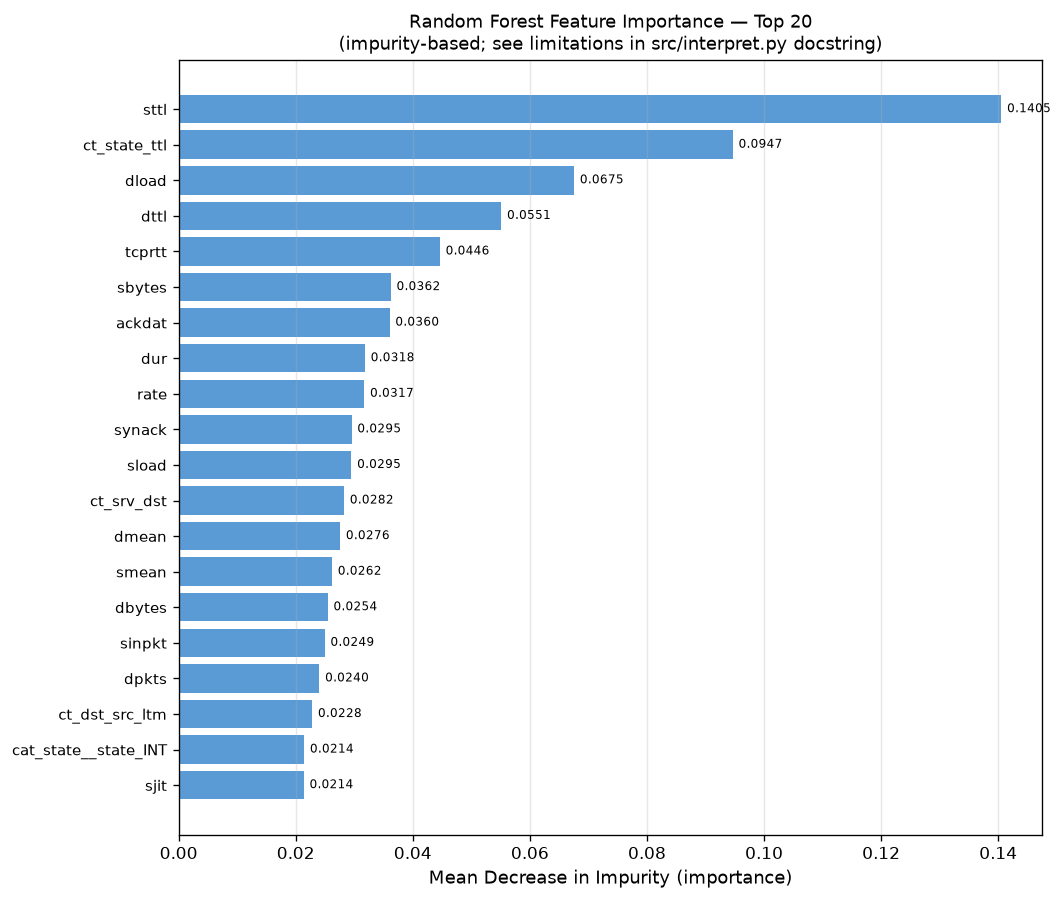

In [6]:
fi_path = FIGURES_DIR / 'feature_importance_rf.png'
if fi_path.exists():
    display(Image(filename=str(fi_path), width=700))

In [7]:
interp = json.loads((METRICS_DIR / 'interpretation_summary.json').read_text())
fi_records = interp['feature_importances'][:15]
fi_df = pd.DataFrame(fi_records)
fi_df['feature_short'] = fi_df['feature'].str.replace(r'^[^_]+__', '', regex=True)
display(fi_df[['rank', 'feature_short', 'importance']].rename(columns={'feature_short': 'feature'}))

,rank,feature,importance
0,1,sttl,0.140518
1,2,ct_state_ttl,0.094650
2,3,dload,0.067541
3,4,dttl,0.055102
4,5,tcprtt,0.044607
5,6,sbytes,0.036222
6,7,ackdat,0.036016
7,8,dur,0.031810
8,9,rate,0.031694
9,10,synack,0.029526


**Limitations of impurity-based importance:**

- MDI (mean decrease in impurity) can **overvalue high-cardinality features** like `stcpb`/`dtcpb`.
- When features are **correlated** (e.g. `sttl`/`ct_state_ttl`), importance is split between them — each appears less important than it truly is.
- These values describe how the model uses features, **not causal relationships** to attack behaviour.
- Top feature `sttl` (source TTL) makes network sense: different OS families and attack tools set characteristic TTL values.

## 7. Error analysis (False Positives and False Negatives)

In [8]:
err = interp['error_analysis']
print(f"False Positives (normal predicted as attack): {err['total_fp']:,}")
print(f"False Negatives (attack predicted as normal): {err['total_fn']:,}")
print()
if 'fp_proto_counts' in err:
    print('Top protocols in False Positives:')
    for proto, cnt in list(err['fp_proto_counts'].items())[:5]:
        print(f'  {proto}: {cnt:,}')
print()
if 'fn_proto_counts' in err:
    print('Top protocols in False Negatives (missed attacks):')
    for proto, cnt in list(err['fn_proto_counts'].items())[:5]:
        print(f'  {proto}: {cnt:,}')

False Positives (normal predicted as attack): 9,850
False Negatives (attack predicted as normal): 642

Top protocols in False Positives:
  tcp: 7,137
  udp: 2,709
  igmp: 4

Top protocols in False Negatives (missed attacks):
  tcp: 485
  udp: 157


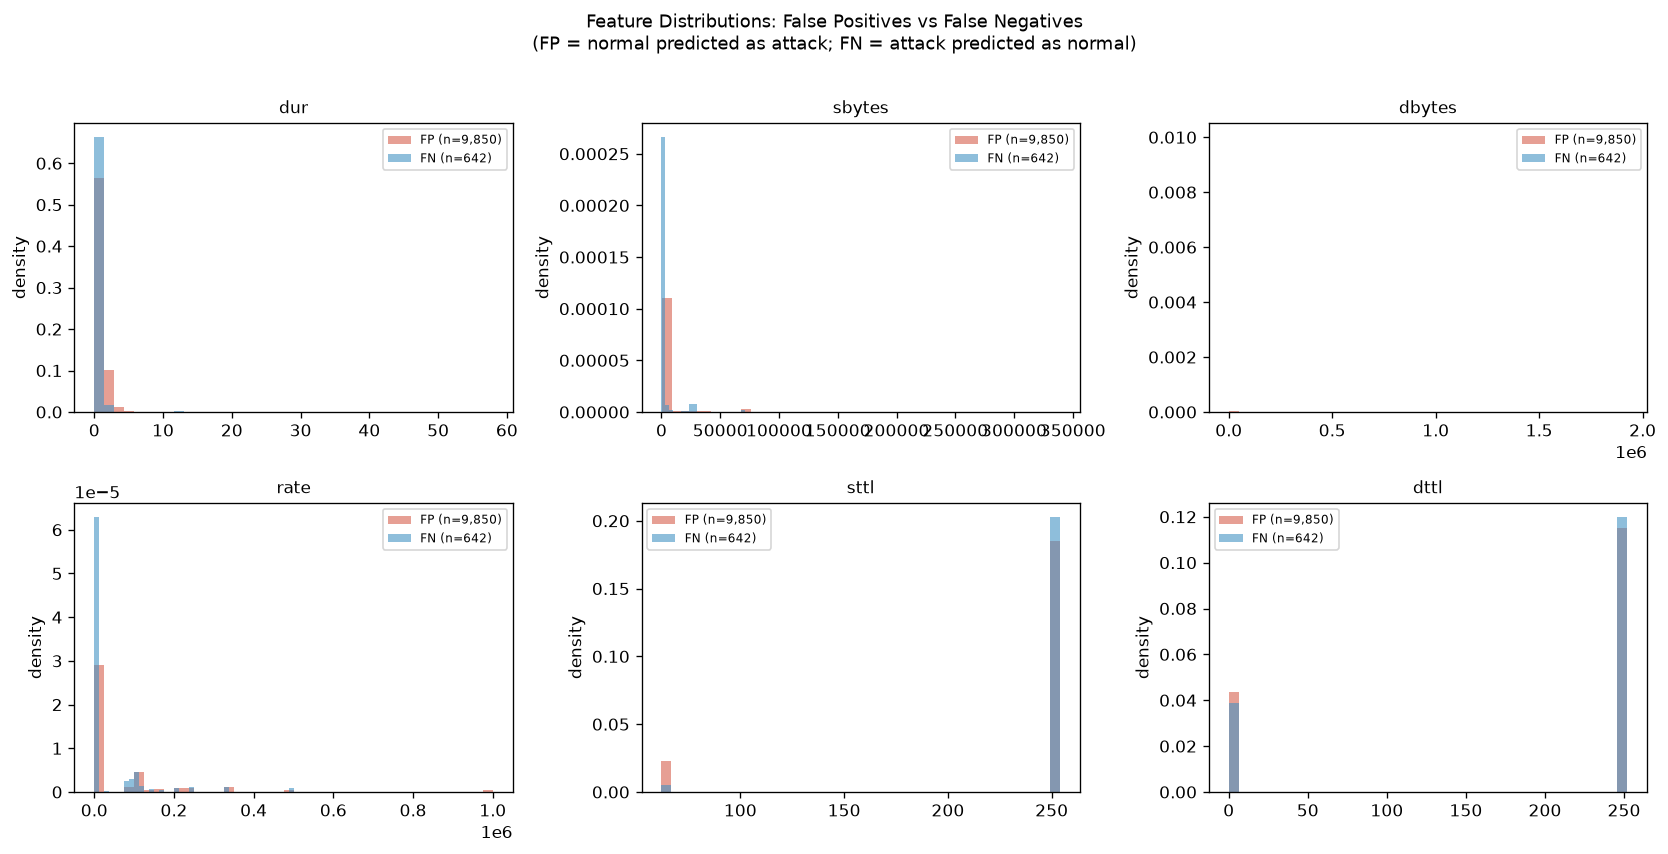

In [9]:
err_path = FIGURES_DIR / 'error_distributions_rf.png'
if err_path.exists():
    display(Image(filename=str(err_path), width=750))

**Error analysis interpretation:**

- The 9,850 **false positives** (normal predicted as attack) are dominated by TCP and UDP traffic — the two most common protocols overall. A threshold adjustment or additional context could reduce alert fatigue.
- The 642 **false negatives** (missed attacks) are also mostly TCP/UDP traffic. These represent attacks whose feature distributions overlap with normal traffic — the hardest cases for any binary classifier.
- The distributions of `dur` and `sbytes` differ between FP and FN rows, suggesting that attack types being missed tend to have longer durations or different byte volumes than those being correctly caught.

## 8. Loading a saved pipeline for new predictions

Each `.joblib` file contains the complete fitted pipeline — preprocessor state plus classifier weights.
No separate preprocessing step is needed.

In [10]:
from src.train import load_pipeline
rf_pipe = load_pipeline(MODELS_DIR / 'RandomForest.joblib')
print('Pipeline loaded:', rf_pipe)
print('Steps:', list(rf_pipe.named_steps.keys()))

Pipeline loaded: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['dur', 'spkts', 'dpkts',
                                                   'sbytes', 'dbytes', 'rate',
                                                   'sttl', 'dttl', 'sload',
                                                   'dload', 'sloss', 'dloss',
                                                   'sinpkt', 'dinpkt', 'sjit',
                                                   'djit', 'swin', 'stcpb',
                                                   'dtcpb', 'dwin', 'tcprtt',
  

## 9. Summary and limitations

| Finding | Detail |
|---|---|
| Best model | Random Forest — Attack Recall 98.6%, Macro F1 0.8665, ROC-AUC 0.9789 |
| Dataset class balance | 68% attacks in training; 55% in testing — inverted vs real networks |
| Top predictive feature | `sttl` (source TTL) — 14.1% impurity importance |
| FN (missed attacks) | 642 — mostly TCP/UDP with borderline features |
| FP (false alarms) | 9,850 — mostly TCP/UDP normal traffic |
| Generalisation caveat | Benchmark performance does not imply real-world detection capability |
| No live monitoring | This is an offline dataset-based prototype only |

**Future work (not implemented):**
- Multiclass attack-category classification using `attack_cat`.
- Threshold tuning to trade FP count vs FN count based on operational priorities.
- Permutation importance to correct for MDI bias on correlated features.
- Evaluation on an independent network capture dataset.